In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
from pathlib import Path


PROJECT_ROOT = Path("/content/drive/MyDrive/master-thesis").resolve()

SRC_PATH = PROJECT_ROOT / "src"
NOTEBOOK_DIR = PROJECT_ROOT / "notebooks"

os.chdir(PROJECT_ROOT)

sys.path.append(str(PROJECT_ROOT))
sys.path.append(str(SRC_PATH))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from notebooks.targeted_experiment_utils import (
    compute_summary_by_setup_and_timing,
    compute_timing_summaries,
    compute_summary_by_setup,
)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("SRC_PATH:", SRC_PATH)
print("Current dir:", Path.cwd())

Mounted at /content/drive
PROJECT_ROOT: /content/drive/MyDrive/master-thesis
SRC_PATH: /content/drive/MyDrive/master-thesis/src
Current dir: /content/drive/MyDrive/master-thesis


In [2]:
def _analyze(results):
    summary_by_setup_and_timing = compute_summary_by_setup_and_timing(results)
    timing_summary, policy_summary = compute_timing_summaries(results)
    setup_summary = compute_summary_by_setup(results)

    print("\n=== Attack Success Rate per setup ===")
    print(summary_by_setup_and_timing.to_string(index=False))

    print("\n=== Setup summary ===")
    print(setup_summary.to_string(index=False))

    print("\n=== Policy summary ===")
    print(policy_summary.to_string(index=False))

    _plot_asr_by_setup(summary_by_setup_and_timing)

In [3]:
def _plot_asr_by_setup(summary: pd.DataFrame):
    plot_data = summary.copy()
    plot_data["label"] = (
        plot_data["setup"] + " / " + plot_data["timing_policy"] + " / " + plot_data["objective"]
    )

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.bar(plot_data["label"], plot_data["nontrivial_attack_success_rate"], color="#2f6f73")
    ax.set_ylabel("Non-trivial Attack Success Rate")
    ax.set_xlabel("ATS setup, timing policy e objective")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=75, labelsize=8)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    results_path = RESULTS_DIR / f"{EXPERIMENT_NAME}_asr_plot"
    plt.savefig(results_path)
    plt.show()

# With validation time

### LSTM - Moving Avarage

Loading results from: /content/drive/MyDrive/master-thesis/notebooks/results_targeted/with_validation_time/ALL_LSTM_MA_2/ALL_LSTM_MA.csv

=== Attack Success Rate per setup ===
                 setup           model strategy          timing_policy  objective  trials  attack_success_rate  baseline_target_rate  nontrivial_trials  nontrivial_successes  mean_min_abs_delta_norm  median_min_abs_delta_norm  mean_delta_final_cr  nontrivial_cr_success  mean_delta_cumulative_return_in_period  median_delta_cumulative_return_in_period  nontrivial_attack_success_rate  cr_success_rate
        LSTM13y_All_MA            LSTM       MA near_strategy_boundary  force_buy      12             1.000000              0.666667                  4                     4                 0.170833                      0.000            -0.147265                      0                                0.000022                                  0.000000                        1.000000            0.000
         LSTM3y_All_MA

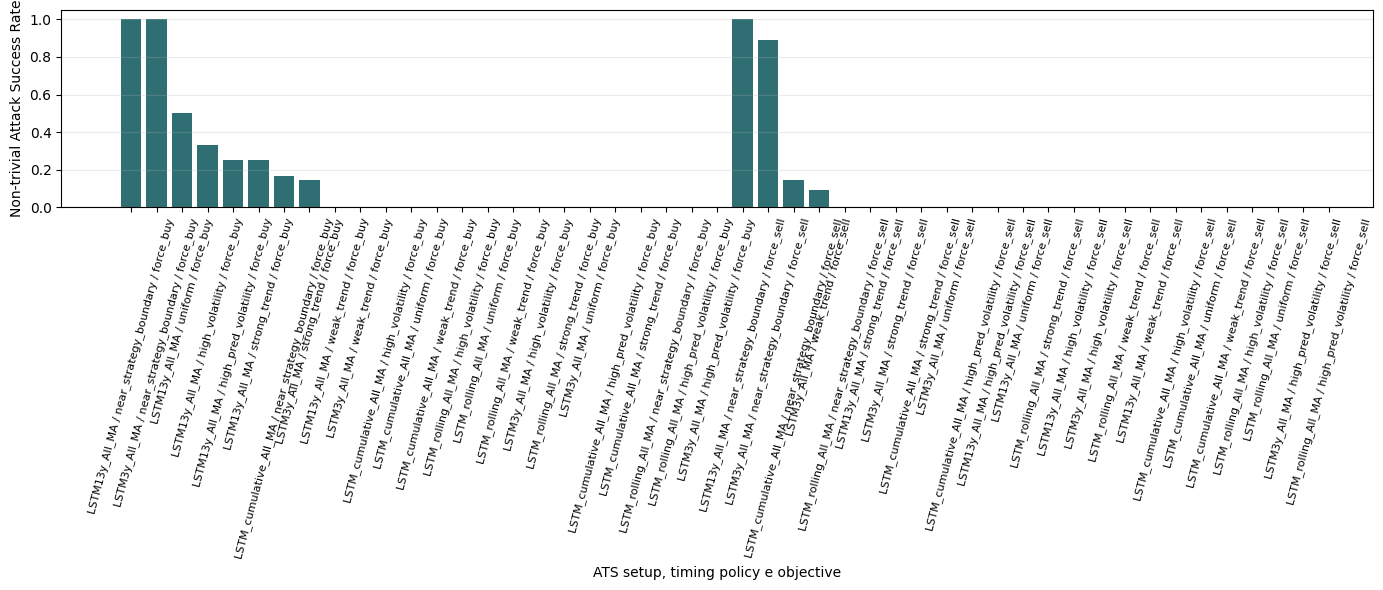

In [4]:
RESULTS_DIR = NOTEBOOK_DIR / "results_targeted/with_validation_time/ALL_LSTM_MA_2"
EXPERIMENT_NAME = "ALL_LSTM_MA"

# Load results
results_path = RESULTS_DIR / f"{EXPERIMENT_NAME}.csv"
if results_path.exists():
    print(f"Loading results from: {results_path}")
    results = pd.read_csv(results_path)
else:
    print(f"Error: {results_path} not found.")

_analyze(results)

### LSTM - Rate Of Change

Loading results from: /content/drive/MyDrive/master-thesis/notebooks/results_targeted/with_validation_time/ALL_LSTM_ROC_2/ALL_LSTM_ROC.csv


/content/drive/MyDrive/master-thesis/notebooks/targeted_experiment_utils.py:1317: RuntimeWarning: Mean of empty slice
  "mean_abs_prediction_shift": ("prediction_shift", lambda x: np.nanmean(np.abs(x))),



=== Attack Success Rate per setup ===
                  setup           model strategy          timing_policy  objective  trials  attack_success_rate  baseline_target_rate  nontrivial_trials  nontrivial_successes  mean_min_abs_delta_norm  median_min_abs_delta_norm  mean_delta_final_cr  nontrivial_cr_success  mean_delta_cumulative_return_in_period  median_delta_cumulative_return_in_period  nontrivial_attack_success_rate  cr_success_rate
        LSTM13y_All_ROC            LSTM      ROC   high_pred_volatility  force_buy      12             1.000000              0.750000                  3                     3                 0.125000                      0.000             0.000000                      0                                0.000000                                  0.000000                        1.000000         0.000000
        LSTM13y_All_ROC            LSTM      ROC        high_volatility  force_buy      12             1.000000              0.750000                  3     

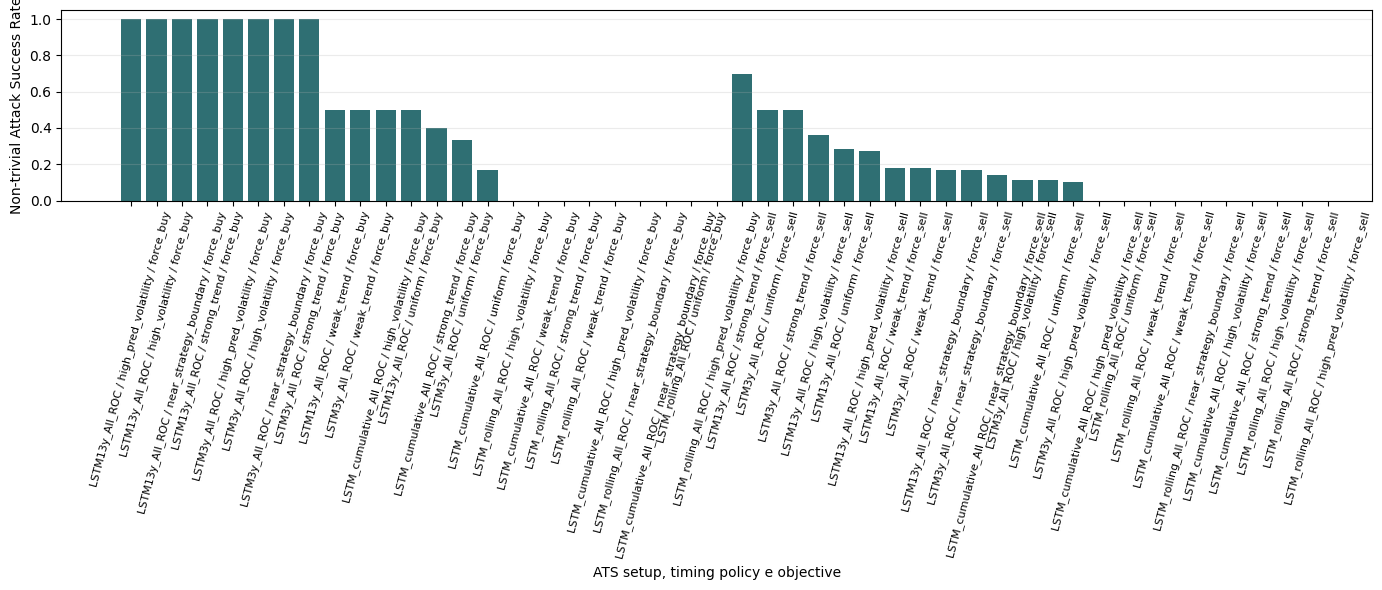

In [5]:
RESULTS_DIR = NOTEBOOK_DIR / "results_targeted/with_validation_time/ALL_LSTM_ROC_2"
EXPERIMENT_NAME = "ALL_LSTM_ROC"

# Load results
results_path = RESULTS_DIR / f"{EXPERIMENT_NAME}.csv"
if results_path.exists():
    print(f"Loading results from: {results_path}")
    results = pd.read_csv(results_path)
else:
    print(f"Error: {results_path} not found.")

_analyze(results)

### LSTM - Bollinger Bands

Loading results from: /content/drive/MyDrive/master-thesis/notebooks/results_targeted/with_validation_time/ALL_LSTM_BB_2/ALL_LSTM_BB.csv


/content/drive/MyDrive/master-thesis/notebooks/targeted_experiment_utils.py:1317: RuntimeWarning: Mean of empty slice
  "mean_abs_prediction_shift": ("prediction_shift", lambda x: np.nanmean(np.abs(x))),



=== Attack Success Rate per setup ===
                 setup           model strategy          timing_policy  objective  trials  attack_success_rate  baseline_target_rate  nontrivial_trials  nontrivial_successes  mean_min_abs_delta_norm  median_min_abs_delta_norm  mean_delta_final_cr  nontrivial_cr_success  mean_delta_cumulative_return_in_period  median_delta_cumulative_return_in_period  nontrivial_attack_success_rate  cr_success_rate
        LSTM13y_All_BB            LSTM       BB           strong_trend  force_buy      12             0.833333              0.833333                  2                     0                      0.0                        0.0                  0.0                      0                                     0.0                                       0.0                             0.0              NaN
   LSTM_rolling_All_BB    LSTM_rolling       BB        high_volatility  force_buy      12             0.666667              0.666667                  4        

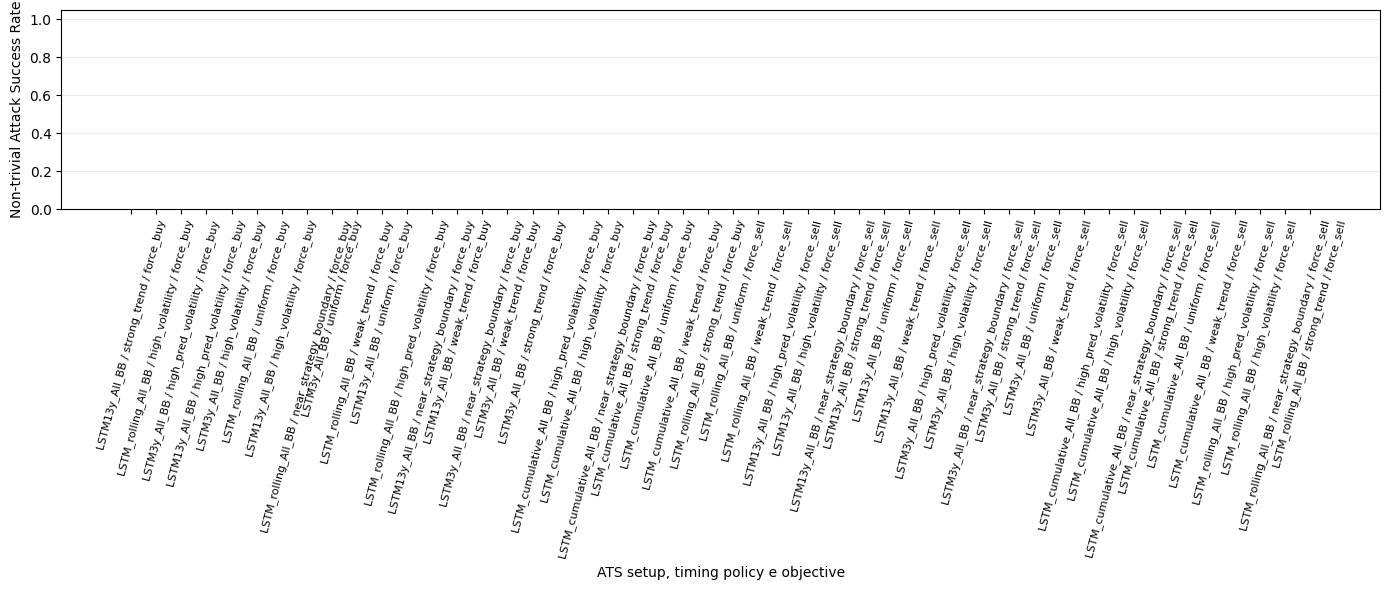

In [6]:
RESULTS_DIR = NOTEBOOK_DIR / "results_targeted/with_validation_time/ALL_LSTM_BB_2"
EXPERIMENT_NAME = "ALL_LSTM_BB"

# Load results
results_path = RESULTS_DIR / f"{EXPERIMENT_NAME}.csv"
if results_path.exists():
    print(f"Loading results from: {results_path}")
    results = pd.read_csv(results_path)
else:
    print(f"Error: {results_path} not found.")

_analyze(results)

# Without validation time

### LSTM - Moving Avarage

Loading results from: /content/drive/MyDrive/master-thesis/notebooks/results_targeted/no_validation_time/ALL_LSTM_MA_2/ALL_LSTM_MA.csv

=== Attack Success Rate per setup ===
                 setup           model strategy          timing_policy  objective  trials  attack_success_rate  baseline_target_rate  nontrivial_trials  nontrivial_successes  mean_min_abs_delta_norm  median_min_abs_delta_norm  mean_delta_final_cr  nontrivial_cr_success  mean_delta_cumulative_return_in_period  median_delta_cumulative_return_in_period  nontrivial_attack_success_rate  cr_success_rate
        LSTM13y_All_MA            LSTM       MA near_strategy_boundary  force_buy      11             0.818182              0.727273                  3                     1                 0.216667                        0.0            -0.007941                      0                                0.000000                                  0.000000                        0.333333              0.0
         LSTM3y_All_MA  

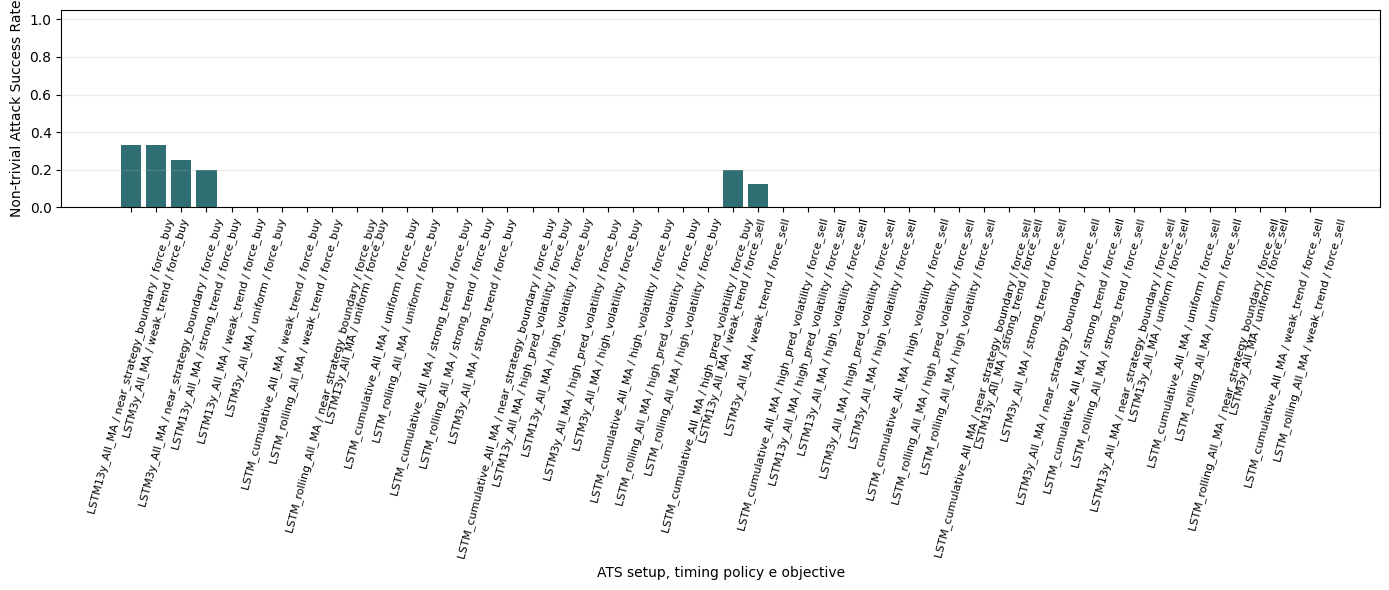

In [7]:
RESULTS_DIR = NOTEBOOK_DIR / "results_targeted/no_validation_time/ALL_LSTM_MA_2"
EXPERIMENT_NAME = "ALL_LSTM_MA"

# Load results
results_path = RESULTS_DIR / f"{EXPERIMENT_NAME}.csv"
if results_path.exists():
    print(f"Loading results from: {results_path}")
    results = pd.read_csv(results_path)
else:
    print(f"Error: {results_path} not found.")

_analyze(results)

### LSTM - Rate Of Change

Loading results from: /content/drive/MyDrive/master-thesis/notebooks/results_targeted/no_validation_time/ALL_LSTM_ROC_2/ALL_LSTM_ROC.csv


/content/drive/MyDrive/master-thesis/notebooks/targeted_experiment_utils.py:1317: RuntimeWarning: Mean of empty slice
  "mean_abs_prediction_shift": ("prediction_shift", lambda x: np.nanmean(np.abs(x))),



=== Attack Success Rate per setup ===
                  setup           model strategy          timing_policy  objective  trials  attack_success_rate  baseline_target_rate  nontrivial_trials  nontrivial_successes  mean_min_abs_delta_norm  median_min_abs_delta_norm  mean_delta_final_cr  nontrivial_cr_success  mean_delta_cumulative_return_in_period  median_delta_cumulative_return_in_period  nontrivial_attack_success_rate  cr_success_rate
         LSTM3y_All_ROC          LSTM3y      ROC near_strategy_boundary  force_buy      11             0.909091              0.363636                  7                     6                 0.465000                      0.350            -0.020170                      2                               -0.000011                                  0.000000                        0.857143         0.333333
        LSTM13y_All_ROC            LSTM      ROC           strong_trend  force_buy      12             0.833333              0.500000                  6     

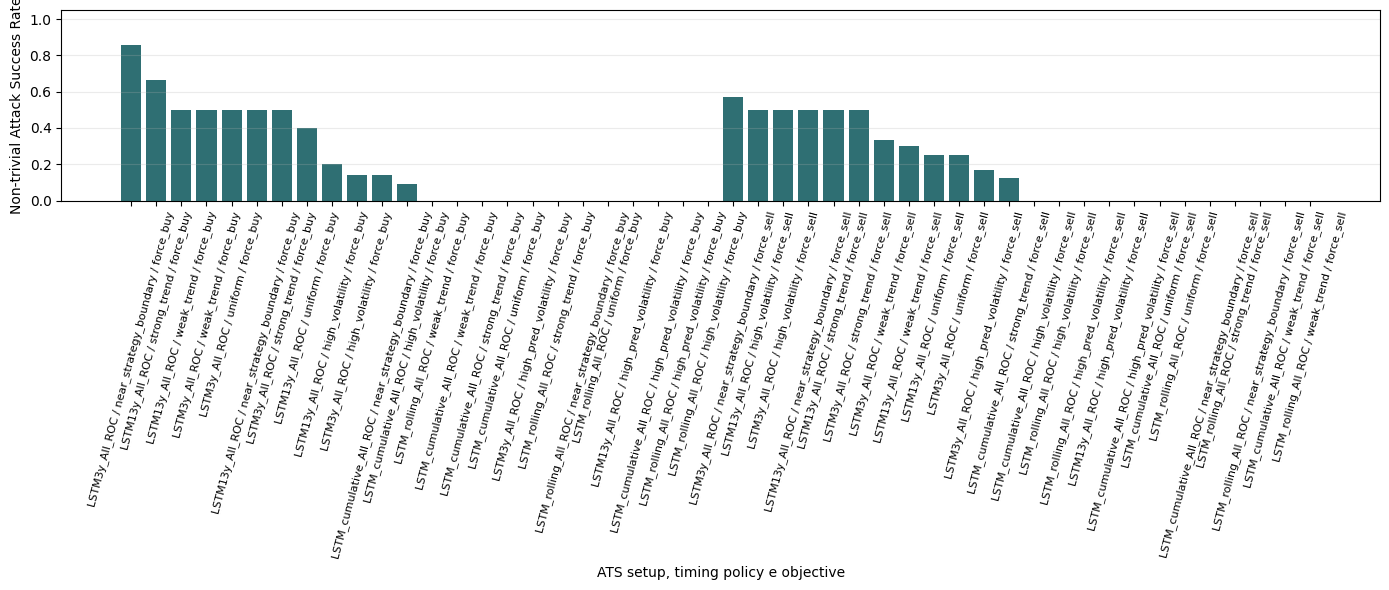

In [8]:
RESULTS_DIR = NOTEBOOK_DIR / "results_targeted/no_validation_time/ALL_LSTM_ROC_2"
EXPERIMENT_NAME = "ALL_LSTM_ROC"

# Load results
results_path = RESULTS_DIR / f"{EXPERIMENT_NAME}.csv"
if results_path.exists():
    print(f"Loading results from: {results_path}")
    results = pd.read_csv(results_path)
else:
    print(f"Error: {results_path} not found.")

_analyze(results)

### LSTM - Bollinger Bands

Loading results from: /content/drive/MyDrive/master-thesis/notebooks/results_targeted/no_validation_time/ALL_LSTM_BB/ALL_LSTM_BB.csv


/content/drive/MyDrive/master-thesis/notebooks/targeted_experiment_utils.py:1317: RuntimeWarning: Mean of empty slice
  "mean_abs_prediction_shift": ("prediction_shift", lambda x: np.nanmean(np.abs(x))),



=== Attack Success Rate per setup ===
                 setup           model strategy          timing_policy  objective  trials  attack_success_rate  baseline_target_rate  nontrivial_trials  nontrivial_successes  mean_min_abs_delta_norm  median_min_abs_delta_norm  mean_delta_final_cr  nontrivial_attack_success_rate
   LSTM_rolling_All_BB    LSTM_rolling       BB   high_pred_volatility  force_buy      12             0.666667              0.666667                  4                     0                      0.0                        0.0                  0.0                             0.0
   LSTM_rolling_All_BB    LSTM_rolling       BB        high_volatility  force_buy      12             0.583333              0.583333                  5                     0                      0.0                        0.0                  0.0                             0.0
   LSTM_rolling_All_BB    LSTM_rolling       BB near_strategy_boundary  force_buy      12             0.583333              

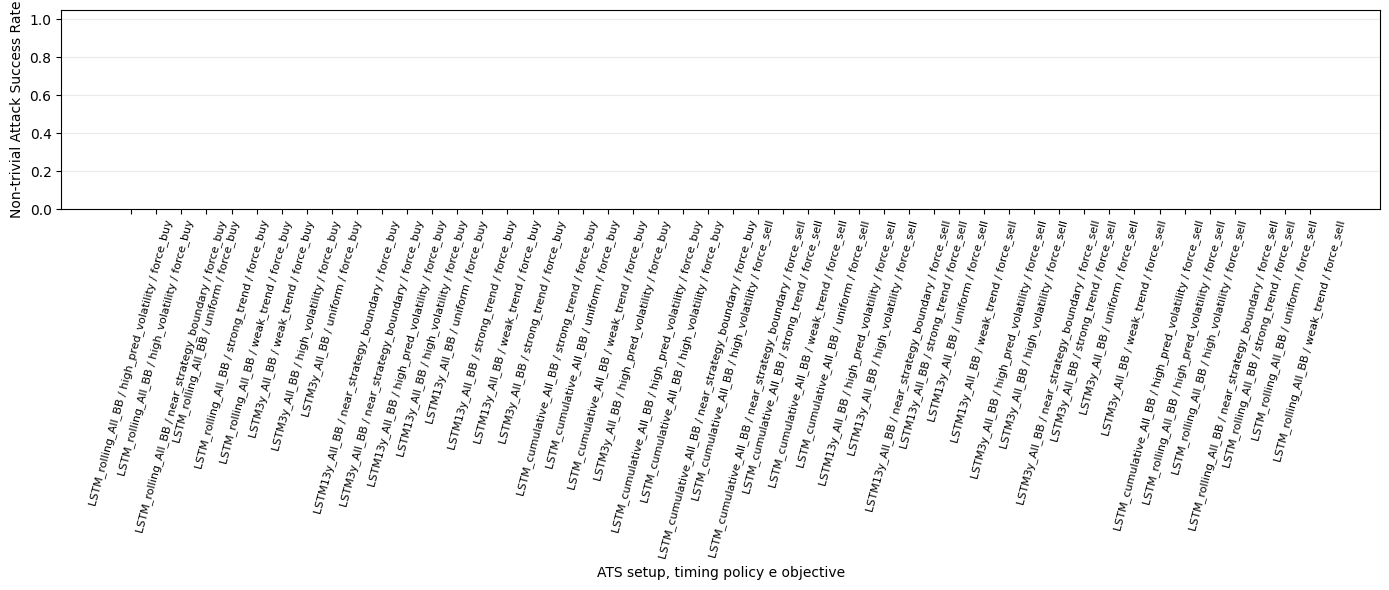

In [ ]:
RESULTS_DIR = NOTEBOOK_DIR / "results_targeted/no_validation_time/ALL_LSTM_BB_2"
EXPERIMENT_NAME = "ALL_LSTM_BB"

# Load results
results_path = RESULTS_DIR / f"{EXPERIMENT_NAME}.csv"
if results_path.exists():
    print(f"Loading results from: {results_path}")
    results = pd.read_csv(results_path)
else:
    print(f"Error: {results_path} not found.")

_analyze(results)